In [1]:
# ============================================================
# CELL 1: IMPORT VÀ NẠP DỮ LIỆU
# ============================================================

import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
import os

# Đường dẫn (tính từ src/)
SPLIT_DIR = "../data/splits/"
MODEL_DIR = "../models/"
OUTPUT_DIR = "../outputs/"
PROCESSED_DIR = "../data/processed/"

# Đọc tập test
X_test = pd.read_csv(f"{SPLIT_DIR}X_test.csv")
y_test = pd.read_csv(f"{SPLIT_DIR}y_test.csv").squeeze("columns")

# Đọc model đã huấn luyện
model = XGBClassifier()
model.load_model(f"{MODEL_DIR}xgboost_model.json")

print("=" * 60)
print("NẠP DỮ LIỆU VÀ MODEL")
print("=" * 60)
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"Số đặc trưng model: {model.n_features_in_}")
print(f"Số đặc trưng X_test: {X_test.shape[1]}")
assert model.n_features_in_ == X_test.shape[1], "Số đặc trưng không khớp!"

print(f"\nPhân bố nhãn test:")
print(y_test.value_counts().to_string())

/home/dungx/Workspace/AI_ML_Projects/ICU_Mortality_Prediction/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NẠP DỮ LIỆU VÀ MODEL
X_test shape: (466, 23)
y_test shape: (466,)
Số đặc trưng model: 23
Số đặc trưng X_test: 23

Phân bố nhãn test:
mortality
0    428
1     38


In [9]:
# ============================================================
# CELL 2: TÍNH SHAP VALUES TRONG KHÔNG GIAN XÁC SUẤT
# ============================================================

print("Đang tính SHAP values (probability space)...")

# Cần background dataset để SHAP chuyển đổi từ log-odds sang xác suất
background = shap.sample(X_test, 50, random_state=42)

explainer = shap.TreeExplainer(
    model,
    data=background,                 # ← bắt buộc khi dùng model_output="probability"
    model_output="probability",      # ← chuyển sang không gian xác suất
    feature_perturbation="interventional",
)
shap_values = explainer(X_test)
print("✅ Tính xong!")

print("\n" + "=" * 60)
print("THÔNG TIN SHAP VALUES")
print("=" * 60)
print(f"Shape SHAP values: {shap_values.values.shape}")
print(f"  (kỳ vọng: {X_test.shape[0]} bệnh nhân × {X_test.shape[1]} đặc trưng)")
print(f"\nBase value (xác suất nền): {explainer.expected_value:.4f}")

# Kiểm tra tính cộng trong không gian xác suất:
#   f(x) = base_value + tổng(SHAP values)
y_pred_proba = model.predict_proba(X_test)[:, 1]
shap_sum = shap_values.values.sum(axis=1)
pred_from_shap = explainer.expected_value + shap_sum

print(f"\nKiểm tra tính cộng (probability space):")
print(f"  max |pred_from_shap - y_pred_proba|: "
      f"{np.abs(pred_from_shap - y_pred_proba).max():.6f}")
print(f"  → Nếu < 0.001, SHAP values khớp hoàn toàn với dự đoán")

Đang tính SHAP values (probability space)...
✅ Tính xong!

THÔNG TIN SHAP VALUES
Shape SHAP values: (466, 23)
  (kỳ vọng: 466 bệnh nhân × 23 đặc trưng)

Base value (xác suất nền): 0.3026

Kiểm tra tính cộng (probability space):
  max |pred_from_shap - y_pred_proba|: 0.000000
  → Nếu < 0.001, SHAP values khớp hoàn toàn với dự đoán


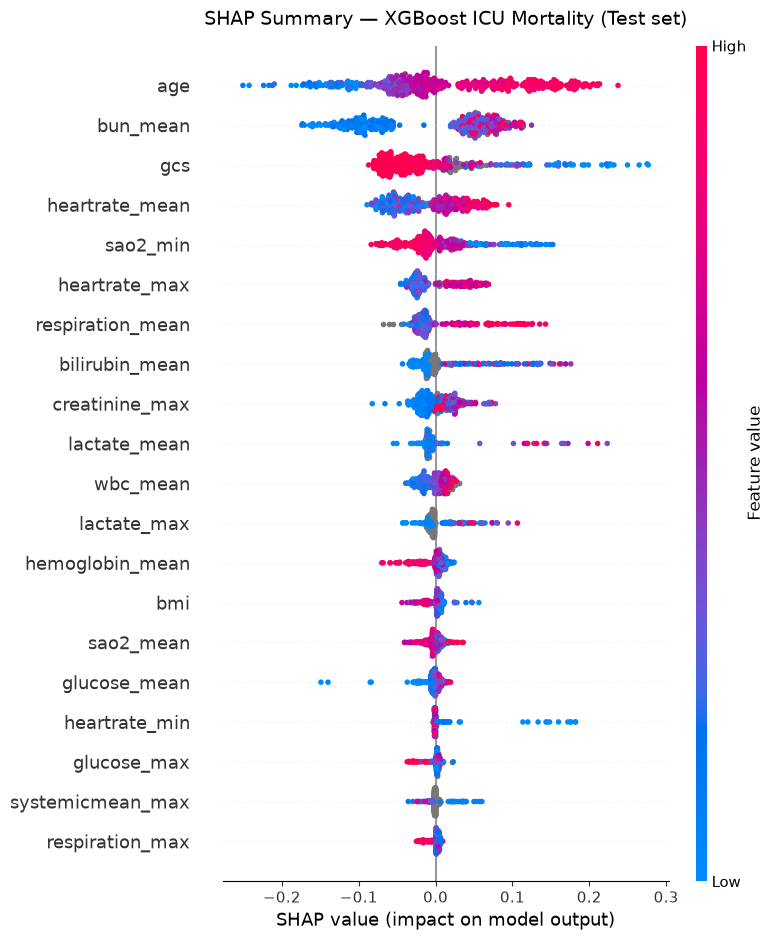

✅ Đã lưu: ../outputs/plots/shap_summary_beeswarm.png


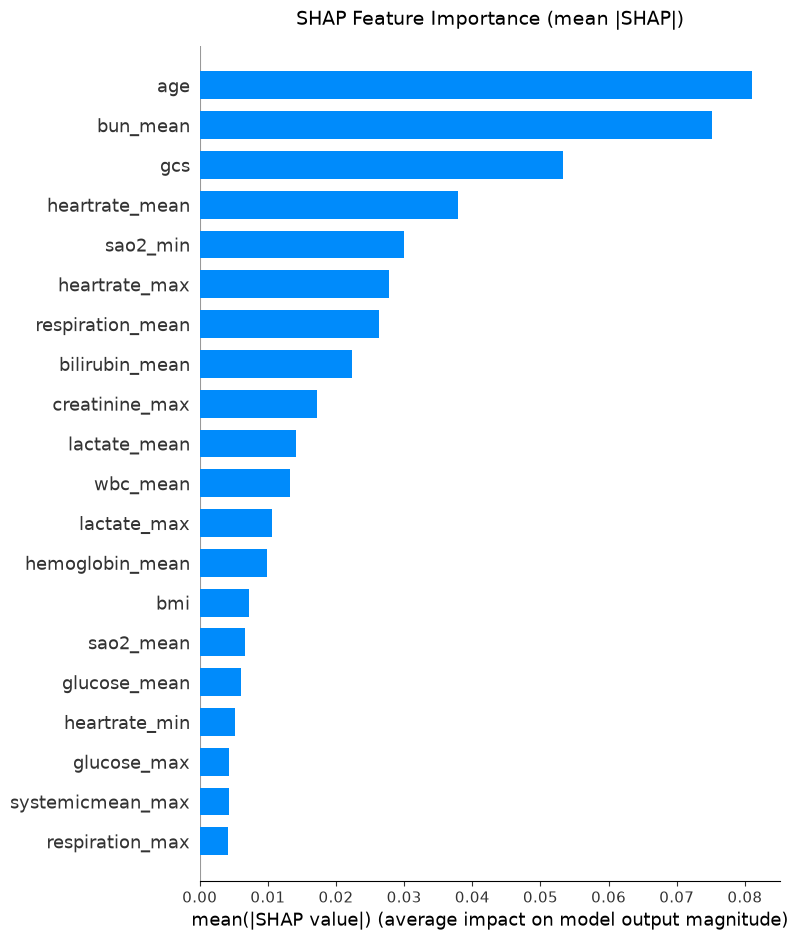

✅ Đã lưu: ../outputs/plots/shap_summary_bar.png


In [10]:
# ============================================================
# CELL 3: VẼ SUMMARY PLOT VÀ BAR PLOT
# ============================================================

os.makedirs(f"{OUTPUT_DIR}plots/", exist_ok=True)

# ---------- Beeswarm plot ----------
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Summary — XGBoost ICU Mortality (Test set)",
          fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}plots/shap_summary_beeswarm.png",
            dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Đã lưu: {OUTPUT_DIR}plots/shap_summary_beeswarm.png")

# ---------- Bar plot ----------
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance (mean |SHAP|)",
          fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}plots/shap_summary_bar.png",
            dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Đã lưu: {OUTPUT_DIR}plots/shap_summary_bar.png")

In [6]:
# ============================================================
# CELL 4: TRÍCH TOP-5 SHAP KÈM GIÁ TRỊ
# ============================================================
# Với mỗi bệnh nhân, lưu 5 bộ ba:
#   - tên đặc trưng (shap_top{i}_name)
#   - giá trị SHAP   (shap_top{i}_value)   — dương = tăng nguy cơ
#   - giá trị thực tế (shap_top{i}_feature) — bệnh nhân có giá trị gì

N_TOP = 5

# Dự đoán xác suất
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Lấy danh sách patientunitstayid theo đúng thứ tự X_test
df_ai_ready = pd.read_csv(f"{PROCESSED_DIR}ai_ready.csv")
test_ids = df_ai_ready.loc[X_test.index, "patientunitstayid"].values

records = []

for i in range(len(X_test)):
    # Lấy SHAP value và feature value của bệnh nhân i
    shap_row = shap_values.values[i]  # mảng 23 SHAP values
    feat_row = X_test.iloc[i].values  # mảng 23 giá trị thực tế

    # Sắp xếp theo |SHAP| giảm dần
    top_indices = np.argsort(np.abs(shap_row))[-N_TOP:][::-1]

    # Xây dựng record
    record = {
        "patientunitstayid": test_ids[i],
        "y_true": int(y_test.iloc[i]),
        "y_pred_proba": round(float(y_pred_proba[i]), 4),
    }

    for rank, idx in enumerate(top_indices, start=1):
        feature_name = X_test.columns[idx]
        shap_val = shap_row[idx]
        feat_val = feat_row[idx]
        record[f"shap_top{rank}_name"] = feature_name
        record[f"shap_top{rank}_value"] = round(float(shap_val), 4)
        # feature value có thể là NaN (rất nhiều NaN trong dữ liệu ICU)
        record[f"shap_top{rank}_feature"] = (
            round(float(feat_val), 2) if not pd.isna(feat_val) else np.nan
        )

    records.append(record)

df_top5 = pd.DataFrame(records)

print("=" * 60)
print("TRÍCH TOP-5 SHAP KÈM GIÁ TRỊ")
print("=" * 60)
print(f"Kích thước: {df_top5.shape}")
print(f"Số cột: {len(df_top5.columns)}")
print(f"\nDanh sách cột:")
for c in df_top5.columns:
    print(f"  {c}")

print(f"\n5 dòng đầu tiên (chỉ hiển thị cột shap_top1):")
display(df_top5[["patientunitstayid", "y_true", "y_pred_proba",
                 "shap_top1_name", "shap_top1_value",
                 "shap_top1_feature"]].head())

# Lưu file
OUTPUT_CSV = f"{OUTPUT_DIR}test_shap_top5.csv"
df_top5.to_csv(OUTPUT_CSV, index=False)
print(f"\n✅ Đã lưu: {OUTPUT_CSV}")

TRÍCH TOP-5 SHAP KÈM GIÁ TRỊ
Kích thước: (466, 18)
Số cột: 18

Danh sách cột:
  patientunitstayid
  y_true
  y_pred_proba
  shap_top1_name
  shap_top1_value
  shap_top1_feature
  shap_top2_name
  shap_top2_value
  shap_top2_feature
  shap_top3_name
  shap_top3_value
  shap_top3_feature
  shap_top4_name
  shap_top4_value
  shap_top4_feature
  shap_top5_name
  shap_top5_value
  shap_top5_feature

5 dòng đầu tiên (chỉ hiển thị cột shap_top1):


,patientunitstayid,y_true,y_pred_proba,shap_top1_name,shap_top1_value,shap_top1_feature
0,141764,0,0.1534,gcs,-0.4671,15.0
1,141765,0,0.1609,gcs,0.9570,5.0
2,143870,0,0.2489,bun_mean,0.3322,31.0
3,144815,0,0.0796,age,-1.3999,39.0
4,145427,0,0.0467,bun_mean,-1.3202,9.0



✅ Đã lưu: ../outputs/test_shap_top5.csv


Bệnh nhân có nguy cơ cao nhất (index 48):
  patientunitstayid : 172015
  Xác suất dự đoán  : 0.9767
  Nhãn thật         : 1 (Tử vong)


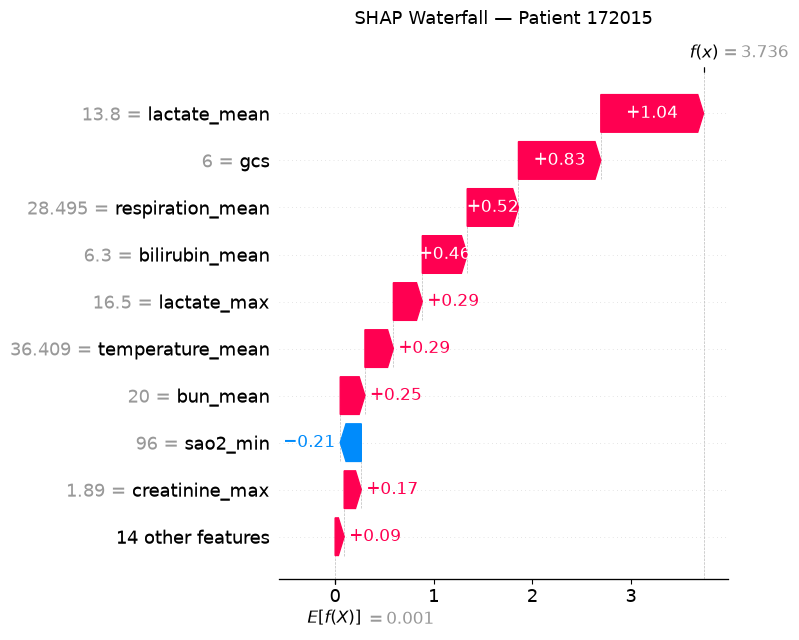

✅ Đã lưu waterfall plot


In [7]:
# ============================================================
# CELL 5: WATERFALL PLOT CHO BỆNH NHÂN CỤ THỂ
# ============================================================

# Chọn bệnh nhân có nguy cơ tử vong cao nhất trong test (để minh họa)
i_max_risk = np.argmax(y_pred_proba)
print(f"Bệnh nhân có nguy cơ cao nhất (index {i_max_risk}):")
print(f"  patientunitstayid : {test_ids[i_max_risk]}")
print(f"  Xác suất dự đoán  : {y_pred_proba[i_max_risk]:.4f}")
print(f"  Nhãn thật         : {y_test.iloc[i_max_risk]} "
      f"({'Tử vong' if y_test.iloc[i_max_risk] == 1 else 'Sống'})")

plt.figure(figsize=(10, 6))
shap.waterfall_plot(shap_values[i_max_risk], max_display=10, show=False)
plt.title(f"SHAP Waterfall — Patient {test_ids[i_max_risk]}",
          fontsize=13, pad=15)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}plots/shap_waterfall_patient_{test_ids[i_max_risk]}.png",
            dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Đã lưu waterfall plot")